# Multi-site harmonization with traveling subjects

Quantitative read-outs that are pooled across **sites, scanners, instruments or assay
platforms** — MRI imaging-derived phenotypes (regional volumes, cortical thickness, QSM
susceptibility, diffusion FA/MD), radiomic features, plate-reader or immunoassay values —
carry a **device offset**: the same person measured on two scanners gives two different
numbers. If the case/control mix also differs between sites (one hospital recruits mostly
patients, another mostly controls), the device offset and the biology are **confounded**,
and a naive pooled analysis reports scanner differences as disease effects.

The cleanest way to separate the two is a **traveling-subject** (a.k.a. "travelling
phantom / human phantom") design: a small cohort of the *same* healthy people is measured on
every device. Because the subject is identical, any difference between devices on that
subject is the device. `ov.bulk` provides three functions for this design:

| Function | What it does |
|---|---|
| `ov.bulk.multisite_harmonize` | fits the two-way **subject + device** model on traveling-subject data and returns one additive offset per device and feature, shrunk with empirical Bayes along the device hierarchy (scanner → model → vendor) |
| `ov.bulk.apply_multisite_harmonization` | applies the frozen offsets (`corrected = raw + offset`) to any new rows — the site-local cohorts — with fallbacks for devices that were never in the fit |
| `ov.bulk.predict_device_offsets` | predicts the offset of an **unseen** device from its acquisition metadata (field strength, voxel size, software ...) by empirical-Bayes kriging within its parent (vendor) |

**Principle.** For a feature, the equal-weight mean of subject *s* on device *d* is modelled
as

$$\bar y_{sd} = \mu_s + \beta_d + \varepsilon_{sd}.$$

The subject term $\mu_s$ absorbs everything biological, so $\beta_d$ is *only* the device.
Subjects need not visit every device — the design only has to be **connected** (every device
reachable from every other through shared subjects). With few traveling subjects the OLS
$\hat\beta_d$ are noisy, so they are shrunk — not toward zero, but **toward the parent**:
a scanner toward its model, a model toward its vendor, a vendor toward the global mean, each
with a method-of-moments variance component $\tau_b^2$ (pooled within user-given feature
families). Offsets are centred over devices: the harmonized scale is the *average device*.

**When to use it.** Whenever you *have* traveling subjects (or phantoms, or a bridging
reference sample run on every platform). If you do not, you have to fall back on ComBat-type
methods that estimate the site effect from the site-local data themselves — and must then
model the biological covariates correctly (section 5 shows why).

This tutorial simulates a realistic study with a **known ground truth**, so every estimate
can be checked.

In [1]:
import omicverse as ov
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
ov.plot_set()

🔬 Starting plot initialization...
🧬 Detecting GPU devices…
🚫 No GPU devices found (CUDA/MPS/ROCm/XPU)

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 2.3.2   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



## 1. Simulate a multi-vendor study with traveling subjects

Eight MRI scanners from two vendors, two scanner models per vendor, two scanners per model.
Each scanner has acquisition parameters (field strength, voxel size, software major
version). The true device effect on each of 40 features is built hierarchically:

* a **vendor** effect (large),
* a **model-within-vendor** effect (medium),
* a **scanner** deviation that depends smoothly on the voxel size (partial-volume effects
  do exactly this) plus a small idiosyncratic term.

The 40 features come in two families with different noise levels — 20 "volumetric" and 20
"diffusion" phenotypes — which we will pass as `feature_groups` so that variance components
are pooled within each family.

In [2]:
rng = np.random.default_rng(7)
n_feat = 40
features = [f"vol_{i:02d}" for i in range(20)] + [f"dti_{i:02d}" for i in range(20)]
families = {"volumetric": features[:20], "diffusion": features[20:]}
noise_sd = np.r_[np.full(20, 0.25), np.full(20, 0.40)]       # measurement noise per feature

devices = pd.DataFrame({
    "scanner_id":    ["A1-a", "A1-b", "A2-a", "A2-b", "B1-a", "B1-b", "B2-a", "B2-b"],
    "scanner_model": ["A1",   "A1",   "A2",   "A2",   "B1",   "B1",   "B2",   "B2"],
    "vendor":        ["A"] * 4 + ["B"] * 4,
    "field_T":       [3.0, 3.0, 1.5, 1.5, 3.0, 3.0, 3.0, 3.0],
    "voxel_mm":      [1.0, 1.2, 1.0, 1.3, 0.9, 1.1, 1.0, 1.25],
    "software":      [11, 12, 11, 11, 25, 27, 25, 27],
}).set_index("scanner_id")

vendor_eff = {v: rng.normal(0, 0.8, n_feat) for v in "AB"}
model_eff = {m: rng.normal(0, 0.35, n_feat) for m in devices.scanner_model.unique()}
voxel_slope = rng.normal(0, 1.2, n_feat)                     # partial-volume sensitivity
def device_effect(row, rng):
    return (vendor_eff[row.vendor] + model_eff[row.scanner_model]
            + voxel_slope * (row.voxel_mm - 1.1) + rng.normal(0, 0.05, n_feat))
true_eff = pd.DataFrame({d: device_effect(r, rng) for d, r in devices.iterrows()}).T
true_eff.columns = features
true_eff_c = true_eff - true_eff.mean()                      # identifiable (centred) effects
devices

           scanner_model vendor  field_T  voxel_mm  software
scanner_id                                                  
A1-a                  A1      A      3.0      1.00        11
A1-b                  A1      A      3.0      1.20        12
A2-a                  A2      A      1.5      1.00        11
A2-b                  A2      A      1.5      1.30        11
B1-a                  B1      B      3.0      0.90        25
B1-b                  B1      B      3.0      1.10        27
B2-a                  B2      B      3.0      1.00        25
B2-b                  B2      B      3.0      1.25        27

**Traveling subjects.** Fifteen healthy volunteers; twelve form the *training* panel and each
visits a random subset of five or six scanners (some with a repeat scan) — an unbalanced but
connected design, as in real traveling-subject studies where not everyone can travel
everywhere. Three more volunteers visit *all* eight scanners and are kept aside to test the
correction on people the fit never saw.

In [3]:
def measure(subject_mu, dev, rng, disease=None):
    y = subject_mu + true_eff.loc[dev].to_numpy() + rng.normal(0, noise_sd)
    if disease is not None:
        y = y + disease
    return y

def make_subject(rng):
    return rng.normal(0, 1.0, n_feat)                        # between-subject biology

rows = []
trav_mu = {f"T{i:02d}": make_subject(rng) for i in range(15)}
train_trav, test_trav = list(trav_mu)[:12], list(trav_mu)[12:]
for s in train_trav:
    visited = rng.choice(devices.index, size=rng.integers(5, 7), replace=False)
    for d in visited:
        for rep in range(1 + int(rng.random() < 0.25)):
            rows.append({"subject_id": s, "scanner_id": d, "repeat": rep,
                         **dict(zip(features, measure(trav_mu[s], d, rng)))})
for s in test_trav:
    for d in devices.index:
        rows.append({"subject_id": s, "scanner_id": d, "repeat": 0,
                     **dict(zip(features, measure(trav_mu[s], d, rng)))})
trav = pd.DataFrame(rows).merge(devices[["scanner_model", "vendor"]], left_on="scanner_id",
                                right_index=True)
train = trav[trav.subject_id.isin(train_trav)]
test = trav[trav.subject_id.isin(test_trav)]
pd.crosstab(train.subject_id, train.scanner_id)

scanner_id  A1-a  A1-b  A2-a  A2-b  B1-a  B1-b  B2-a  B2-b
subject_id                                                
T00            2     0     1     1     0     1     0     1
T01            2     0     0     1     1     1     1     0
T02            0     0     1     2     1     0     2     1
T03            1     0     1     1     2     1     1     0
T04            2     1     0     1     1     1     0     2
T05            1     1     1     0     1     0     0     1
T06            2     1     0     0     1     0     1     2
T07            1     1     0     0     1     1     0     1
T08            1     2     1     1     0     1     0     1
T09            1     2     1     1     0     2     0     0
T10            2     0     1     2     2     1     0     1
T11            2     0     1     0     1     2     1     0

The table counts scans per training subject and scanner: zeros are scanners a subject never
visited, twos are repeat scans. No scanner is visited by everyone, yet the bipartite
subject–scanner graph is connected, so all scanner offsets are identifiable relative to one
another.

**Site-local cohorts.** Each scanner also scans 40 of its own subjects, patients and
controls. The disease lowers the first 10 volumetric features by 0.5 units (true effect),
and — the crux — **patient prevalence is confounded with vendor**: 85 % patients at the vendor A
sites (say, the specialist clinics) and 15 % at the vendor B sites (population-based
recruitment).

In [4]:
disease_effect = np.zeros(n_feat); disease_effect[:10] = -0.5
local_rows = []
for d, r in devices.iterrows():
    p_case = 0.85 if r.vendor == "A" else 0.15
    for k in range(40):
        case = rng.random() < p_case
        y = measure(make_subject(rng), d, rng, disease_effect if case else None)
        local_rows.append({"subject_id": f"{d}_L{k:02d}", "scanner_id": d,
                           "scanner_model": r.scanner_model, "vendor": r.vendor,
                           "group": "patient" if case else "control",
                           **dict(zip(features, y))})
local = pd.DataFrame(local_rows)
pd.crosstab(local.vendor, local.group)

group   control  patient
vendor                  
A            23      137
B           135       25

## 2. Fit the device offsets with `multisite_harmonize`

We pass the training traveling-subject table, the feature list, the hierarchy from finest to
coarsest parent (`['scanner_model', 'vendor']`), the feature families for variance pooling,
and the device metadata table (stored in the fit for later prediction of unseen devices).
For comparison we also fit with `shrinkage='none'` — plain two-way OLS.

In [5]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)   # no unseen devices yet -> fallback warning
    fit = ov.bulk.multisite_harmonize(
        train, features, subject_key="subject_id", device_key="scanner_id",
        hierarchy=["scanner_model", "vendor"], feature_groups=families,
        device_table=devices)
    fit_ols = ov.bulk.multisite_harmonize(
        train, features, subject_key="subject_id", device_key="scanner_id",
        hierarchy=["scanner_model", "vendor"], feature_groups=families,
        device_table=devices, shrinkage="none")
print(fit["method"])
print("cells (subject x scanner):", fit["n_cells"])
fit["offsets"].iloc[:, [0, 1, 20, 21]].round(3)

two-way subject+device model on equal-weight cell means; hierarchical_eb shrinkage along scanner_id/scanner_model/vendor (pool=variance, ratio_scale=1)
cells (subject x scanner): 64


            vol_00  vol_01  dti_00  dti_01
scanner_id                                
A1-a        -0.131   0.172   0.907  -0.022
A1-b        -0.039  -0.064   1.093  -0.017
A2-a        -0.260   0.220   0.601  -0.092
A2-b        -0.147  -0.037   0.590  -0.293
B1-a         0.043   0.280  -0.798   0.159
B1-b         0.011  -0.071  -0.704   0.077
B2-a         0.233  -0.249  -0.723   0.215
B2-b         0.292  -0.252  -0.966  -0.027

`fit['offsets']` is a scanners × features table; a harmonized value is `raw + offset`, i.e.
the measurement re-expressed on the scale of the *average scanner*. `fit['effects']` holds
the same numbers with the opposite sign (the device effect). Other entries worth knowing:

* `fit['ratios']` — the shrinkage strength $\sigma^2/\tau_b^2$ of each hierarchy block
  (large = that level shows little real spread beyond noise, so it is pulled hard toward the
  parent);
* `fit['fallback_offsets']` — mean offsets per model and per vendor, used for devices that
  were never in the fit;
* `fit['residual_variance']` — the per-feature noise $\sigma^2$ left after the two-way model.

In [6]:
fit["ratios"].T.groupby(lambda f: f[:3]).mean().T.round(3)

                                  dti    vol
device_within_scanner_model:A1  4.342  1.116
device_within_scanner_model:A2  3.124  0.362
device_within_scanner_model:B1  6.766  0.970
device_within_scanner_model:B2  3.051  0.605
scanner_model_within_vendor:A   1.081  0.230
scanner_model_within_vendor:B   0.628  0.156
vendor_within_global            0.061  0.020

Shrinkage strength per block, averaged within each family (`vol` / `dti`). The vendor and
model blocks have large true spread, so their ratios are small (little shrinkage); the
scanner-within-model blocks carry only the voxel-size term and small idiosyncratic noise,
so they are shrunk more — exactly the behaviour the hierarchy is meant to give.

### Check against the truth

Because we simulated the data, we can compare the estimated device effects with the true
centred effects.

In [7]:
def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
truth = true_eff_c.loc[fit["effects"].index, features]
summary = pd.DataFrame({
    "corr with truth": [np.corrcoef(f["effects"].to_numpy().ravel(), truth.to_numpy().ravel())[0, 1]
                        for f in (fit_ols, fit)],
    "RMSE": [rmse(f["effects"], truth) for f in (fit_ols, fit)],
}, index=["two-way OLS (shrinkage='none')", "hierarchical EB (default)"])
summary.round(4)

                                corr with truth    RMSE
two-way OLS (shrinkage='none')           0.9842  0.1112
hierarchical EB (default)                0.9850  0.1070

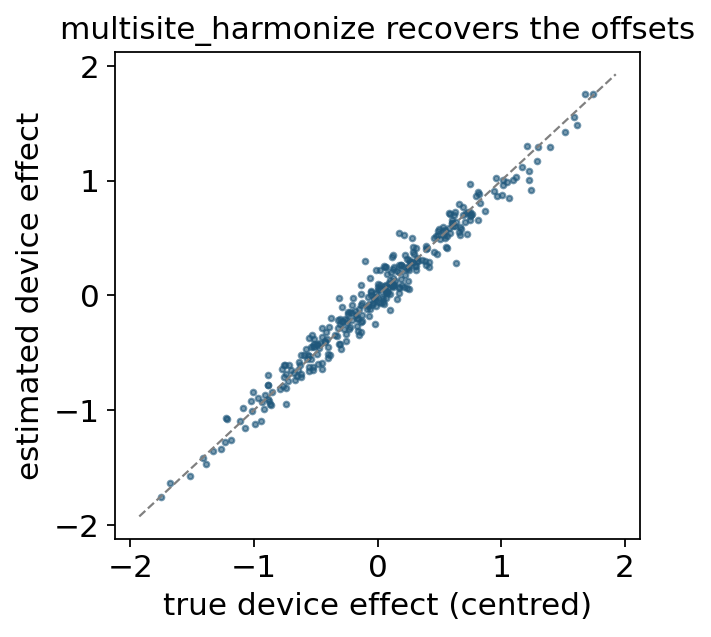

In [8]:
fig, ax = plt.subplots(figsize=(4.2, 4))
ax.scatter(truth.to_numpy().ravel(), fit["effects"].to_numpy().ravel(), s=6, alpha=0.6)
lim = np.abs(truth.to_numpy()).max() * 1.1
ax.plot([-lim, lim], [-lim, lim], color="grey", lw=1, ls="--")
ax.set_xlabel("true device effect (centred)"); ax.set_ylabel("estimated device effect")
ax.set_title("multisite_harmonize recovers the offsets")
plt.show()

The 320 device × feature effects lie on the identity line. Hierarchical EB is at least as
accurate as plain OLS here; its advantage grows as traveling subjects get fewer or noisier,
because a noisy scanner estimate is pulled toward its model and vendor rather than taken at
face value.

## 3. Apply the offsets to held-out traveling subjects

The three test volunteers were scanned on all eight scanners but never used in the fit.
Their between-scanner spread is pure device effect plus noise, so it is the most direct
test of a harmonization: after correction, the same person should give the same number
everywhere (down to the measurement noise).

In [9]:
test_h = ov.bulk.apply_multisite_harmonization(test, fit)
def within_subject_sd(df):
    return df.groupby("subject_id")[features].std().mean()
repro = pd.DataFrame({"raw": within_subject_sd(test), "harmonized": within_subject_sd(test_h),
                      "noise floor": pd.Series(noise_sd, index=features)})
repro.groupby(lambda f: f[:3]).mean().round(3)

       raw  harmonized  noise floor
dti  0.708       0.394         0.40
vol  0.673       0.254         0.25

Before correction the across-scanner SD of the same person is several times the
measurement noise; after correction it sits at the noise floor (the SD expected from the
simulated noise alone). Device effects have been removed for people the fit never saw, which
is what matters when the offsets are applied to the site-local cohorts.

## 4. Harmonize the site-local cohorts

Now the main use: the clinical cohorts, scanned only once, at their local site.

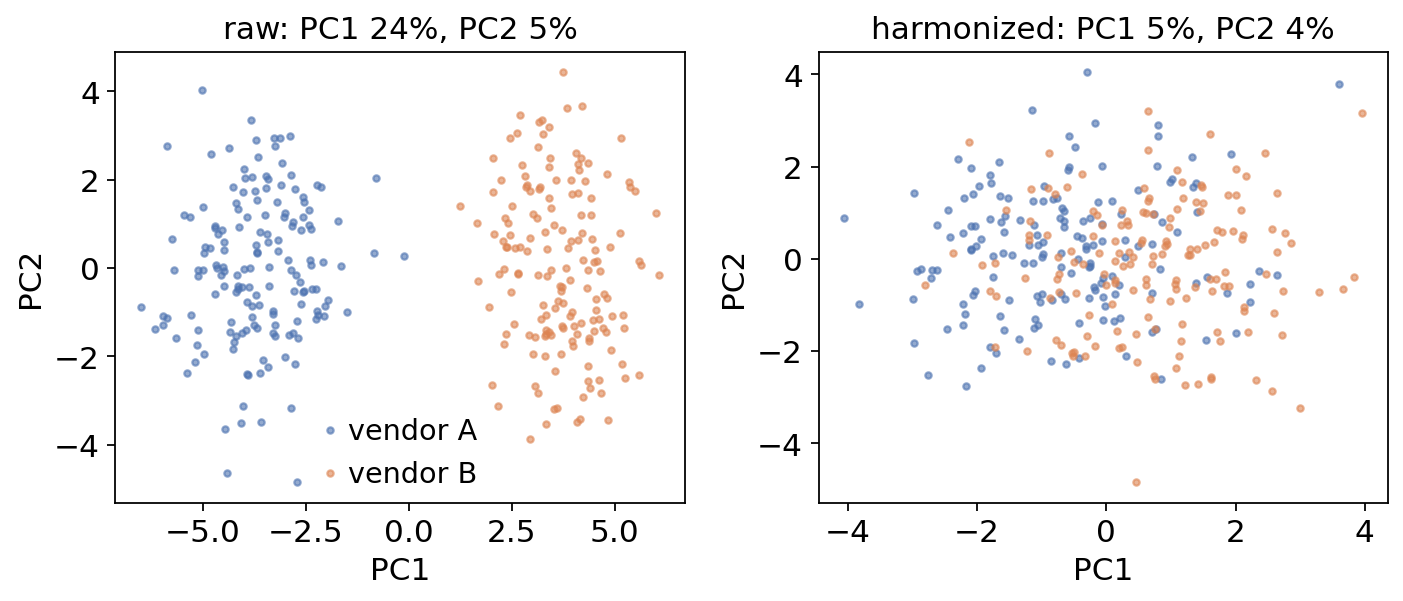

In [10]:
local_h = ov.bulk.apply_multisite_harmonization(local, fit)

def pca2(X):
    Xc = X - X.mean(0)
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    return Xc @ Vt[:2].T, (S[:2] ** 2 / (S ** 2).sum())

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
colors = {"A": "#4C72B0", "B": "#DD8452"}
for ax, (name, df) in zip(axes, [("raw", local), ("harmonized", local_h)]):
    pc, ev = pca2(df[features].to_numpy())
    for v in "AB":
        m = (df.vendor == v).to_numpy()
        ax.scatter(pc[m, 0], pc[m, 1], s=8, alpha=0.6, c=colors[v], label=f"vendor {v}")
    ax.set_title(f"{name}: PC1 {ev[0]:.0%}, PC2 {ev[1]:.0%}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

On the raw values the first principal component separates the two vendors — the dominant
axis of variation in the pooled data is the scanner, not the people. After harmonization the
vendors overlap. A quantitative version: the fraction of each feature's variance explained by
the scanner (one-way $R^2$), computed **within controls only** so that the confounded
disease does not contribute.

In [11]:
def site_r2(df):
    ctrl = df[df.group == "control"]
    tot = ctrl[features].var(ddof=0)
    within = ctrl.groupby("scanner_id")[features].transform(lambda x: x - x.mean()).var(ddof=0)
    return 1 - within / tot
pd.DataFrame({"raw": site_r2(local), "harmonized": site_r2(local_h)}).describe().loc[
    ["mean", "50%", "max"]].round(3)

        raw  harmonized
mean  0.190       0.048
50%   0.179       0.043
max   0.629       0.098

The scanner explains a large share of variance in the raw controls and essentially none
after correction (what remains is sampling noise of 40-subject site means).

### Recovery of the disease effect

The question the study was run for: how large is the patient–control difference? We
estimate it per feature as the pooled difference in means. The truth is −0.5 on the first
10 features and 0 on the other 30.

In [12]:
def group_diff(df):
    g = df.groupby("group")[features].mean()
    return g.loc["patient"] - g.loc["control"]

# a naive "remove the site mean" correction (what location-only ComBat without covariates does)
local_centered = local.copy()
local_centered[features] = local.groupby("scanner_id")[features].transform(lambda x: x - x.mean())

est = pd.DataFrame({
    "truth": disease_effect,
    "raw pooled": group_diff(local).to_numpy(),
    "site-mean centring": group_diff(local_centered).to_numpy(),
    "traveling-subject harmonized": group_diff(local_h).to_numpy(),
}, index=features)
err = pd.DataFrame({c: [est[c][:10].mean(), rmse(est[c][:10], est.truth[:10]), rmse(est[c][10:], 0)]
                    for c in est.columns[1:]},
                   index=["mean effect, affected (truth -0.5)", "RMSE, affected features",
                          "RMSE, null features"])
err.round(3)

                                    raw pooled  site-mean centring  \
mean effect, affected (truth -0.5)      -0.785              -0.255   
RMSE, affected features                  0.759               0.255   
RMSE, null features                      0.783               0.076   

                                    traveling-subject harmonized  
mean effect, affected (truth -0.5)                        -0.562  
RMSE, affected features                                    0.104  
RMSE, null features                                        0.116  

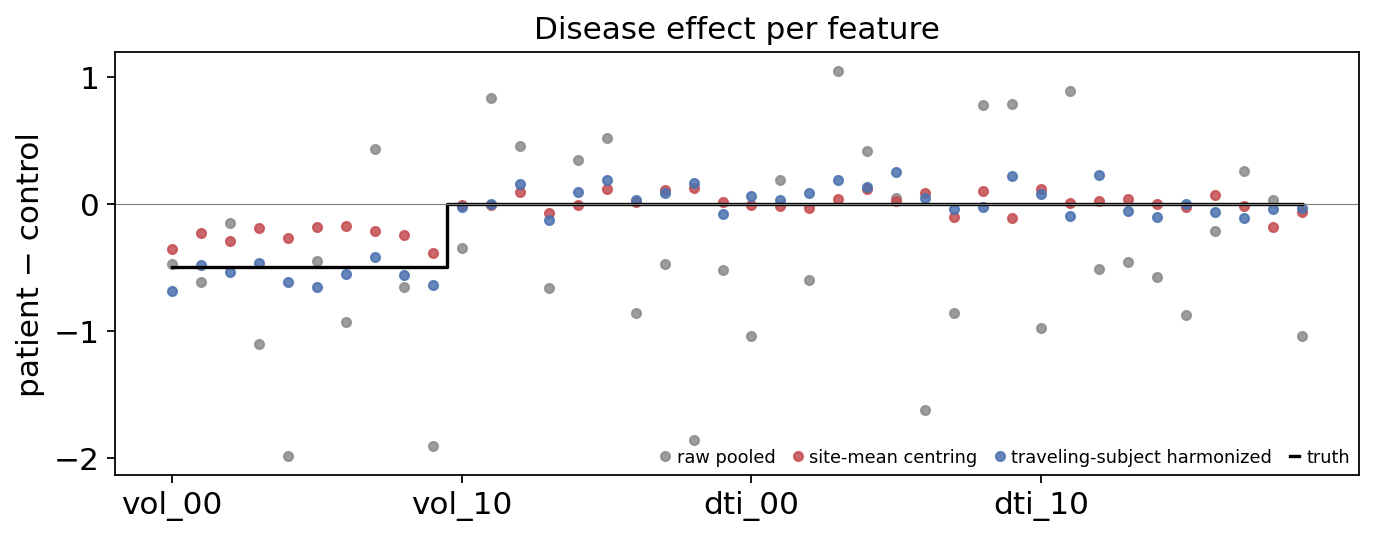

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(n_feat)
for k, (c, col) in enumerate(zip(est.columns[1:], ["#8C8C8C", "#C44E52", "#4C72B0"])):
    ax.plot(x, est[c], "o", ms=4, color=col, label=c, alpha=0.85)
ax.step(x, est.truth, where="mid", color="black", lw=1.5, label="truth")
ax.axhline(0, color="grey", lw=0.5)
ax.set_xticks([0, 10, 20, 30]); ax.set_xticklabels(["vol_00", "vol_10", "dti_00", "dti_10"])
ax.set_ylabel("patient − control"); ax.legend(frameon=False, ncol=4, fontsize=8, loc="lower right")
ax.set_title("Disease effect per feature")
plt.tight_layout(); plt.show()

* **Raw pooled** (grey): because patients are over-represented at vendor A, every vendor A−B
  difference leaks into the patient–control contrast — the null features show spurious
  "effects" as large as the real one.
* **Site-mean centring** (red): removing each site's mean removes the site effect, but the
  site mean also contains the site's patient fraction, so part of the real disease effect is
  removed with it — the true effect is **attenuated** (biased toward 0). With prevalences of
  85 % vs 15 % the expected pooled estimate is only about half of the truth
  ($1 - (\bar p_{\text{cases}} - \bar p_{\text{controls}}) = 1 - (0.745 - 0.255) \approx 0.51$),
  while the null features look clean — a silent, not a visible, failure.
* **Traveling-subject harmonization** (blue): the offsets come from people whose biology is
  held fixed across scanners, so they contain no disease signal; the real effect is recovered
  without bias and the null features scatter around 0.

Note the price: the harmonized estimates are not noise-free. Each offset is estimated from a
dozen traveling subjects, and that estimation error (`fit['offset_variance']`) propagates into
every corrected value — visible as the spread of the blue points around the truth. More
traveling subjects, or repeat scans, shrink it; a biased estimate does not get better with
more patients.

## 5. A contrast with ComBat

ComBat (`ov.bulk.batch_correction`, a wrapper of pyComBat) estimates the batch location and
scale from the site-local data themselves, with an empirical-Bayes prior across features.
Without covariates its location step is essentially the site-mean centring above, so it
inherits the same attenuation under confounding. ComBat *can* protect biology if the
covariate (here, diagnosis) is put in the model — neuroComBat does this — but then (i) every
biological variable you later want to test must be known and modelled at harmonization time,
and (ii) when the confounding is severe (a site with almost only patients) the site and
disease terms become nearly collinear and both are estimated poorly. Traveling subjects avoid
the problem by design: the offset is measured on people whose biology does not change.

The two approaches are complementary: when you have traveling subjects, use them for the
offsets; when you have none, use ComBat **with** the biological covariates and check the
confounding table (section 1) first.

## 6. A scanner that was never in the traveling-subject study

Sites upgrade software, replace coils or join late. Suppose a new vendor-A scanner `A2-c`
(model A2, 1.5 T, voxel 1.25 mm, software 11) joins and only scans local subjects. Three
options for its offset:

1. no correction;
2. the **parent mean** — the average offset of the trained A2 scanners
   (`fit['fallback_offsets']['scanner_model']`, what `apply_multisite_harmonization` uses
   when it knows only the model);
3. `predict_device_offsets` — kriging within the parent on the acquisition parameters: the
   new scanner borrows most from trained scanners with similar parameters (here `A2-b`, voxel
   1.3 mm).

In [14]:
new_dev = pd.DataFrame({"scanner_model": ["A2"], "vendor": ["A"], "field_T": [1.5],
                        "voxel_mm": [1.25], "software": [11]}, index=pd.Index(["A2-c"], name="scanner_id"))
true_new = device_effect(new_dev.iloc[0], rng)
true_new_offset = -(true_new - true_eff.mean().to_numpy())     # on the fit's centred scale

pred = ov.bulk.predict_device_offsets(fit, new_dev)
print("parameters compared:", pred["parameters"], " bandwidth:", round(pred["bandwidth"], 3))
print("pooled within:", pred["pool_level"])
pred["weights"]["A2-c"].round(3)

parameters compared: ['field_T', 'voxel_mm', 'software']  bandwidth: 1.369
pooled within: {'A2-c': 'scanner_model'}


A1-a   -0.053
A1-b    0.053
A2-a   -0.181
A2-b    0.181
B1-a   -0.034
B1-b    0.034
B2-a   -0.021
B2-b    0.021
dtype: float64

The weights act on the trained scanners' *deviations from their own parent mean*. Only the
two A2 scanners carry appreciable weight, with opposite signs: the prediction starts at the
A2 mean and is moved toward `A2-b`, whose voxel size (1.3 mm) is closest to the new scanner's
(1.25 mm), and away from `A2-a` (1.0 mm).

In [15]:
cand = {"no correction": np.zeros(n_feat),
        "parent (model) mean": fit["fallback_offsets"]["scanner_model"].loc["A2"].to_numpy(),
        "predict_device_offsets": pred["offsets"].loc["A2-c"].to_numpy()}
pd.Series({k: rmse(v, true_new_offset) for k, v in cand.items()}, name="RMSE vs true offset").round(3)

no correction             0.617
parent (model) mean       0.193
predict_device_offsets    0.164
Name: RMSE vs true offset, dtype: float64

Using the metadata reduces the error compared with the plain parent mean (and both are far
better than no correction), because the
scanner-within-model deviation in this simulation follows the voxel size. When parameters do
not distinguish devices (or the within-parent spread $\tau^2$ is zero) the prediction falls
back to the parent mean automatically.

In practice you pass the metadata once, at fit time (`new_device_table=`) or at apply time,
and the unseen device's rows are corrected with the prediction:

In [16]:
new_rows = pd.DataFrame([{"subject_id": f"A2-c_L{k}", "scanner_id": "A2-c", "scanner_model": "A2",
                          "vendor": "A", **dict(zip(features, make_subject(rng) + true_new
                                                     + rng.normal(0, noise_sd)))} for k in range(5)])
new_h = ov.bulk.apply_multisite_harmonization(new_rows, fit, new_device_table=new_dev)
np.allclose(new_h[features].to_numpy() - new_rows[features].to_numpy(), cand["predict_device_offsets"])

True

## 7. Pitfalls

* **Additive model.** The offsets are additive on the scale you pass in. If a device effect
  is multiplicative (e.g. volumes scaling with a gradient-calibration error), harmonize
  `log` values and back-transform.
* **Connectivity.** The subject–device graph must be connected; otherwise the offsets of two
  disconnected groups of scanners are not comparable and the function raises.
* **Traveling subjects should span the population range.** The model assumes the device
  effect does not depend on the subject (no subject × device interaction). If the device
  effect differs for, e.g., atrophied brains, a healthy-only panel cannot learn it.
* **The hierarchy must nest.** A level that varies within a device or is not nested in the
  next coarser level is dropped with a warning — read the warnings.
* **Unseen devices.** Without metadata, unseen devices get the parent mean, and the function
  warns. Give `new_device_table` / `device_table` whenever a protocol sheet exists.
* **Freeze the fit.** Fit once on the traveling subjects, then apply the same frozen offsets
  to all cohorts; never refit on the clinical data, which would reintroduce the confounding.
* **Uncertainty.** `fit['offset_variance']` gives the sampling variance of each offset; with
  very few traveling subjects it can be comparable to small disease effects.

## 8. References

* Yamashita A, *et al.* (2019). Harmonization of resting-state functional MRI data across
  multiple imaging sites via the separation of site differences into sampling bias and
  measurement bias. *PLoS Biology* 17(4): e3000042. https://doi.org/10.1371/journal.pbio.3000042
* Johnson WE, Li C, Rabinovic A (2007). Adjusting batch effects in microarray expression data
  using empirical Bayes methods. *Biostatistics* 8(1): 118–127.
  https://doi.org/10.1093/biostatistics/kxj037
* Fortin J-P, *et al.* (2018). Harmonization of cortical thickness measurements across
  scanners and sites. *NeuroImage* 167: 104–120. https://doi.org/10.1016/j.neuroimage.2017.11.024
* Morris CN (1983). Parametric empirical Bayes inference: theory and applications. *JASA*
  78(381): 47–55. https://doi.org/10.1080/01621459.1983.10477920